In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Load dataset
file_path = "C:\\Users\\abdal\\OneDrive\\Desktop\\RetailSense_Customer_Analytics\\data\\raw\\Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_analysis)

,Missing_Count,Missing_Percentage
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


In [5]:
total_records = len(df)

total_customers = df["CustomerID"].nunique()

missing_customer_ids = df["CustomerID"].isna().sum()

print("Total Records:", total_records)
print("Unique Customers:", total_customers)
print("Missing CustomerID Rows:", missing_customer_ids)

print(
    "Missing CustomerID Percentage:",
    round(missing_customer_ids / total_records * 100, 2),
    "%"
)

Total Records: 541909
Unique Customers: 4372
Missing CustomerID Rows: 135080
Missing CustomerID Percentage: 24.93 %


In [6]:
# Identify cancelled invoices
cancelled_mask = df["InvoiceNo"].astype(str).str.startswith("C")

# Identify valid purchase rows
valid_mask = (
    ~cancelled_mask
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & df["CustomerID"].notna()
)

purchase_df = df.loc[valid_mask].copy()

# Count unique invoices per customer
customer_orders = (
    purchase_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

# Customers with 2 or more invoices
repeat_customers = customer_orders[customer_orders >= 2]

# Calculate repeat purchase rate
total_identified_customers = len(customer_orders)
total_repeat_customers = len(repeat_customers)

repeat_purchase_rate = (
    total_repeat_customers / total_identified_customers
) * 100

print("Total Identified Customers:", total_identified_customers)
print("Repeat Customers:", total_repeat_customers)
print("Repeat Purchase Rate:", round(repeat_purchase_rate, 2), "%")

Total Identified Customers: 4338
Repeat Customers: 2845
Repeat Purchase Rate: 65.58 %


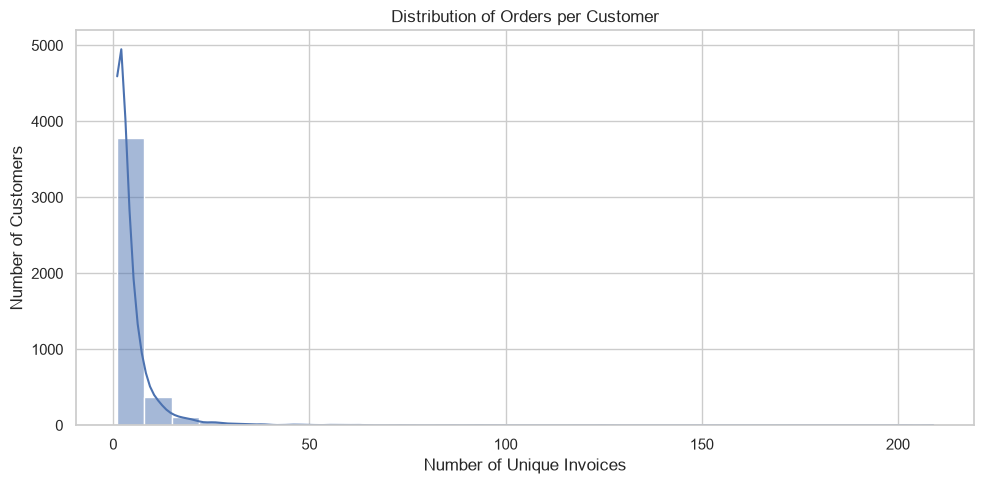

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    customer_orders,
    bins=30,
    kde=True
)

plt.title("Distribution of Orders per Customer")
plt.xlabel("Number of Unique Invoices")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

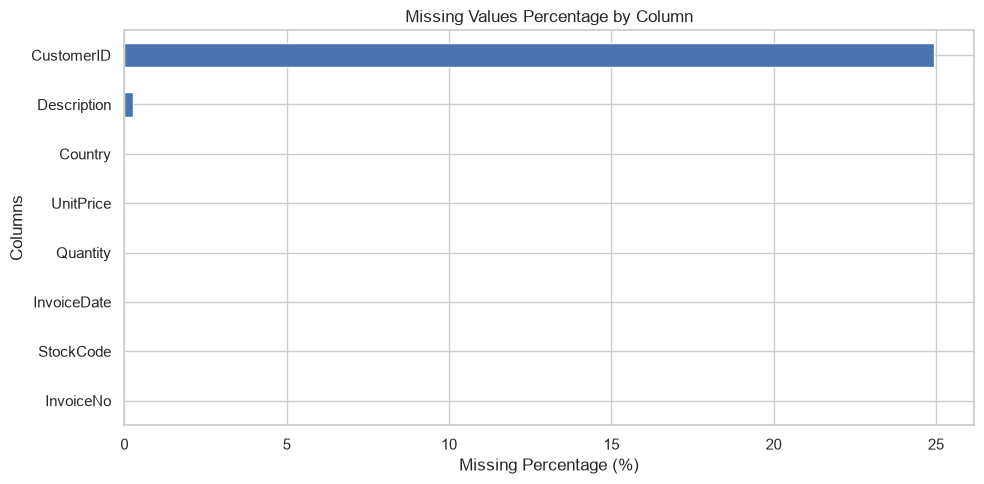

In [8]:
plt.figure(figsize=(10, 5))

missing_analysis["Missing_Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Columns")

plt.tight_layout()
plt.show()

In [9]:
# All customers in the original dataset
all_customer_ids = set(
    df["CustomerID"].dropna().unique()
)

# Customers with valid purchases
valid_customer_ids = set(
    purchase_df["CustomerID"].unique()
)

# Customers excluded from valid purchases
excluded_customer_ids = (
    all_customer_ids - valid_customer_ids
)

print("Original Customers:", len(all_customer_ids))
print("Valid Purchase Customers:", len(valid_customer_ids))
print("Excluded Customers:", len(excluded_customer_ids))

Original Customers: 4372
Valid Purchase Customers: 4338
Excluded Customers: 34


In [10]:

# =========================================
# IDENTIFY CUSTOMERS EXCLUDED FROM RFM
# =========================================

# Work on a copy and remove exact duplicates
df_base = df.drop_duplicates().copy()

# Identify valid purchase rows
valid_purchase_mask = (
    ~df_base["InvoiceNo"].astype(str).str.strip().str.upper().str.startswith("C")
    & (df_base["Quantity"] > 0)
    & (df_base["UnitPrice"] > 0)
    & (df_base["CustomerID"].notna())
)

# Get customers who have at least one valid purchase
valid_customer_ids = set(
    df_base.loc[valid_purchase_mask, "CustomerID"].unique()
)

# Get all identified customers
all_customer_ids = set(
    df_base["CustomerID"].dropna().unique()
)

# Customers without any valid purchase
excluded_customer_ids = (
    all_customer_ids - valid_customer_ids
)

# Keep all their transaction rows for diagnosis
excluded_customers_df = df_base[
    df_base["CustomerID"].isin(excluded_customer_ids)
].copy()

print("Total Identified Customers:", len(all_customer_ids))
print("Eligible Customers:", len(valid_customer_ids))
print("Excluded Customers:", len(excluded_customer_ids))
print("Excluded Transaction Rows:", len(excluded_customers_df))


Total Identified Customers: 4372
Eligible Customers: 4338
Excluded Customers: 34
Excluded Transaction Rows: 89


In [11]:
tmp = excluded_customers_df.copy()

# تحديد الصفوف الملغاة
tmp["Is_Cancelled"] = (
    tmp["InvoiceNo"].astype(str).str.startswith("C")
)

# تحديد الصفوف غير الملغاة
tmp["Is_Non_Cancelled"] = ~tmp["Is_Cancelled"]

# فحص الكمية والسعر
tmp["Positive_Quantity"] = tmp["Quantity"] > 0
tmp["Positive_Price"] = tmp["UnitPrice"] > 0

# الصف الذي يحقق جميع شروط الشراء الصحيح
tmp["Valid_Purchase_Row"] = (
    tmp["Is_Non_Cancelled"]
    & tmp["Positive_Quantity"]
    & tmp["Positive_Price"]
)

# تجميع النتائج لكل عميل
diagnostic = (
    tmp.groupby("CustomerID")
    .agg(
        Total_Rows=("InvoiceNo", "size"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Cancelled_Rows=("Is_Cancelled", "sum"),
        Non_Cancelled_Rows=("Is_Non_Cancelled", "sum"),
        Non_Cancelled_Positive_Quantity=(
            "Positive_Quantity",
            lambda s: (
                s & tmp.loc[s.index, "Is_Non_Cancelled"]
            ).sum()
        ),
        Non_Cancelled_Positive_Price=(
            "Positive_Price",
            lambda s: (
                s & tmp.loc[s.index, "Is_Non_Cancelled"]
            ).sum()
        ),
        Valid_Purchase_Rows=("Valid_Purchase_Row", "sum")
    )
)

display(diagnostic)

,Total_Rows,Unique_Invoices,Cancelled_Rows,Non_Cancelled_Rows,Non_Cancelled_Positive_Quantity,Non_Cancelled_Positive_Price,Valid_Purchase_Rows
CustomerID,,,,,,,
12503.0,1,1,1,0,0,0,0
12505.0,1,1,1,0,0,0,0
12605.0,3,1,3,0,0,0,0
12666.0,2,1,2,0,0,0,0
12870.0,2,1,2,0,0,0,0
12943.0,1,1,1,0,0,0,0
13154.0,1,1,1,0,0,0,0
13256.0,1,1,0,1,1,0,0
13693.0,4,2,4,0,0,0,0


In [12]:
# Create a copy for revenue analysis
revenue_df = df.copy()

# Calculate the value of each row
revenue_df["LineRevenue"] = (
    revenue_df["Quantity"] * revenue_df["UnitPrice"]
)

# Identify cancelled invoices
revenue_df["Is_Cancelled"] = (
    revenue_df["InvoiceNo"].astype(str).str.startswith("C")
)

# Identify valid non-cancelled sales
revenue_df["Is_Valid_Sale"] = (
    ~revenue_df["Is_Cancelled"]
    & (revenue_df["Quantity"] > 0)
    & (revenue_df["UnitPrice"] > 0)
)

# Identify invalid non-cancelled rows
revenue_df["Is_Invalid_Non_Cancelled"] = (
    ~revenue_df["Is_Cancelled"]
    & ~revenue_df["Is_Valid_Sale"]
)

# Build a summary
revenue_summary = pd.DataFrame({
    "Rows": [
        revenue_df["Is_Valid_Sale"].sum(),
        revenue_df["Is_Cancelled"].sum(),
        revenue_df["Is_Invalid_Non_Cancelled"].sum()
    ],
    "Amount_GBP": [
        revenue_df.loc[
            revenue_df["Is_Valid_Sale"], "LineRevenue"
        ].sum(),

        revenue_df.loc[
            revenue_df["Is_Cancelled"], "LineRevenue"
        ].sum(),

        revenue_df.loc[
            revenue_df["Is_Invalid_Non_Cancelled"], "LineRevenue"
        ].sum()
    ]
}, index=[
    "Valid_Non_Cancelled_Sales",
    "Cancelled_Rows",
    "Invalid_Non_Cancelled_Rows"
])

display(revenue_summary)

,Rows,Amount_GBP
Valid_Non_Cancelled_Sales,530104,1.066668e+07
Cancelled_Rows,9288,-8.968125e+05
Invalid_Non_Cancelled_Rows,2517,-2.212412e+04


In [13]:
excluded_revenue = revenue_df[
    revenue_df["CustomerID"].isin(excluded_customer_ids)
].copy()

excluded_revenue_summary = pd.DataFrame({
    "Rows": [
        excluded_revenue["Is_Cancelled"].sum(),
        excluded_revenue["Is_Valid_Sale"].sum(),
        excluded_revenue["Is_Invalid_Non_Cancelled"].sum()
    ],
    "Amount_GBP": [
        excluded_revenue.loc[
            excluded_revenue["Is_Cancelled"], "LineRevenue"
        ].sum(),

        excluded_revenue.loc[
            excluded_revenue["Is_Valid_Sale"], "LineRevenue"
        ].sum(),

        excluded_revenue.loc[
            excluded_revenue["Is_Invalid_Non_Cancelled"], "LineRevenue"
        ].sum()
    ]
}, index=[
    "Cancelled_Rows",
    "Valid_Sales",
    "Invalid_Non_Cancelled_Rows"
])

display(excluded_revenue_summary)

,Rows,Amount_GBP
Cancelled_Rows,88,-10411.24
Valid_Sales,0,0.00
Invalid_Non_Cancelled_Rows,1,0.00


In [14]:
cancelled_data = revenue_df[
    revenue_df["Is_Cancelled"]
]

print("Cancelled rows with negative amount:",
      (cancelled_data["LineRevenue"] < 0).sum())

print("Cancelled rows with positive amount:",
      (cancelled_data["LineRevenue"] > 0).sum())

print("Cancelled rows with zero amount:",
      (cancelled_data["LineRevenue"] == 0).sum())

print("Total signed cancellation amount:",
      cancelled_data["LineRevenue"].sum())

Cancelled rows with negative amount: 9288
Cancelled rows with positive amount: 0
Cancelled rows with zero amount: 0
Total signed cancellation amount: -896812.49


In [15]:
invalid_df = revenue_df[
    revenue_df["Is_Invalid_Non_Cancelled"]
].copy()

# Classify invalid rows
invalid_df["Invalid_Reason"] = np.select(
    [
        (invalid_df["Quantity"] <= 0)
        & (invalid_df["UnitPrice"] <= 0),

        invalid_df["Quantity"] <= 0,

        invalid_df["UnitPrice"] <= 0
    ],
    [
        "Both_Non_Positive",
        "Non_Positive_Quantity",
        "Non_Positive_Price"
    ],
    default="Other"
)

# Summarize
invalid_summary = (
    invalid_df.groupby("Invalid_Reason")
    .agg(
        Rows=("InvoiceNo", "size"),
        Total_Amount_GBP=("LineRevenue", "sum")
    )
)

display(invalid_summary)

,Rows,Total_Amount_GBP
Invalid_Reason,,
Both_Non_Positive,1336,0.00
Non_Positive_Price,1181,-22124.12


In [16]:
valid_sales = revenue_df.loc[
    revenue_df["Is_Valid_Sale"], "LineRevenue"
].sum()

cancelled_amount = revenue_df.loc[
    revenue_df["Is_Cancelled"], "LineRevenue"
].sum()

invalid_amount = revenue_df.loc[
    revenue_df["Is_Invalid_Non_Cancelled"], "LineRevenue"
].sum()

net_revenue = valid_sales + cancelled_amount

print(f"Valid Sales:       £{valid_sales:,.2f}")
print(f"Cancelled Amount:  £{cancelled_amount:,.2f}")
print(f"Invalid Amount:    £{invalid_amount:,.2f}")
print(f"Net Revenue:       £{net_revenue:,.2f}")


Valid Sales:       £10,666,684.54
Cancelled Amount:  £-896,812.49
Invalid Amount:    £-22,124.12
Net Revenue:       £9,769,872.05


In [17]:
print("Dataset Date Range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

print("\nExact Duplicate Rows:")
print(df.duplicated().sum())

Dataset Date Range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Exact Duplicate Rows:
5268


Day 2

In [18]:
# 1. Filter valid purchases with registered CustomerIDs
purchase_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & (df["CustomerID"].notna())
].copy()

# 2. Calculate revenue for each transaction row
purchase_df["LineRevenue"] = (
    purchase_df["Quantity"] * purchase_df["UnitPrice"]
)

# 3. Aggregate data at customer level
customer_eda = (
    purchase_df.groupby("CustomerID")
    .agg(
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("LineRevenue", "sum")
    )
)

# 4. Display descriptive statistics
display(customer_eda.describe())

,Frequency,Monetary
count,4338.000000,4338.000000
mean,4.272015,2054.266460
std,7.697998,8989.230441
min,1.000000,3.750000
25%,1.000000,307.415000
50%,2.000000,674.485000
75%,5.000000,1661.740000
max,209.000000,280206.020000


In [19]:
# Calculate skewness
print("Frequency Skewness:", customer_eda["Frequency"].skew())
print("Monetary Skewness:", customer_eda["Monetary"].skew())

# Calculate high percentiles
percentiles = customer_eda[["Frequency", "Monetary"]].quantile(
    [0.90, 0.95, 0.99, 0.999]
)

display(percentiles)

Frequency Skewness: 12.067030826322066
Monetary Skewness: 19.324953236820818


,Frequency,Monetary
0.900,9.000,3646.53100
0.950,13.000,5841.84300
0.990,30.000,19880.99570
0.999,92.326,137452.21139


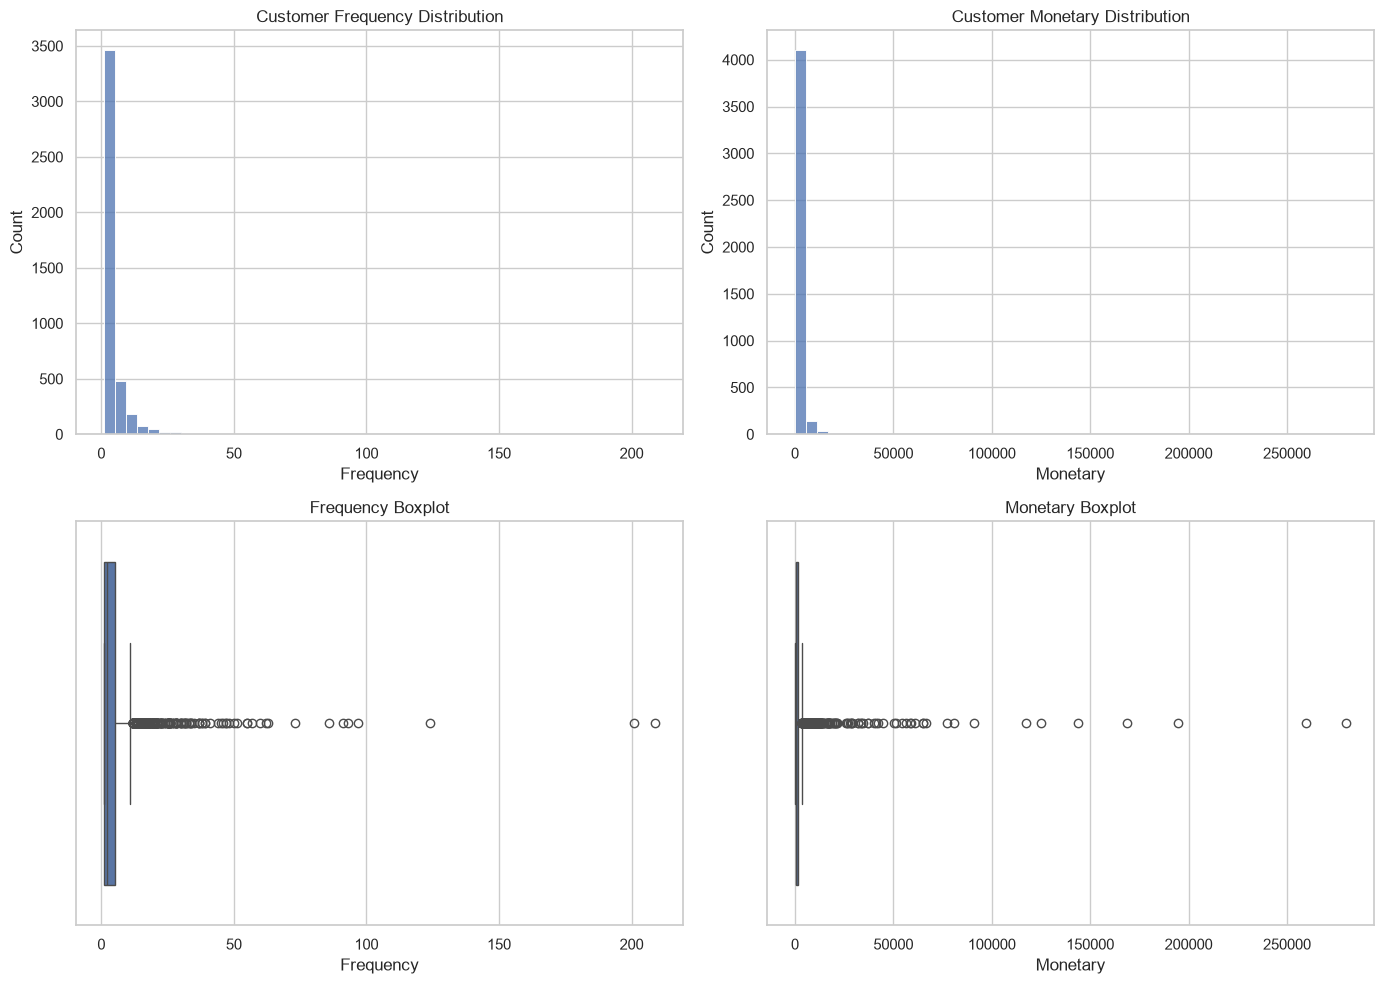

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Frequency distribution
sns.histplot(
    customer_eda["Frequency"],
    bins=50,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Customer Frequency Distribution")

# Monetary distribution
sns.histplot(
    customer_eda["Monetary"],
    bins=50,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Customer Monetary Distribution")

# Frequency boxplot
sns.boxplot(
    x=customer_eda["Frequency"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Frequency Boxplot")

# Monetary boxplot
sns.boxplot(
    x=customer_eda["Monetary"],
    ax=axes[1, 1]
)
axes[1, 1].set_title("Monetary Boxplot")

plt.tight_layout()
plt.show()

In [21]:
customer_eda["Frequency_Log"] = np.log1p(
    customer_eda["Frequency"]
)

customer_eda["Monetary_Log"] = np.log1p(
    customer_eda["Monetary"]
)

In [22]:
print(
    "Frequency Skewness:",
    customer_eda["Frequency"].skew()
)

print(
    "Monetary Skewness:",
    customer_eda["Monetary"].skew()
)

print("\nSkewness After Log Transformation:")

print(
    "Frequency Log:",
    customer_eda["Frequency_Log"].skew()
)

print(
    "Monetary Log:",
    customer_eda["Monetary_Log"].skew()
)

Frequency Skewness: 12.067030826322066
Monetary Skewness: 19.324953236820818

Skewness After Log Transformation:
Frequency Log: 1.2086515045964816
Monetary Log: 0.3935525870343543


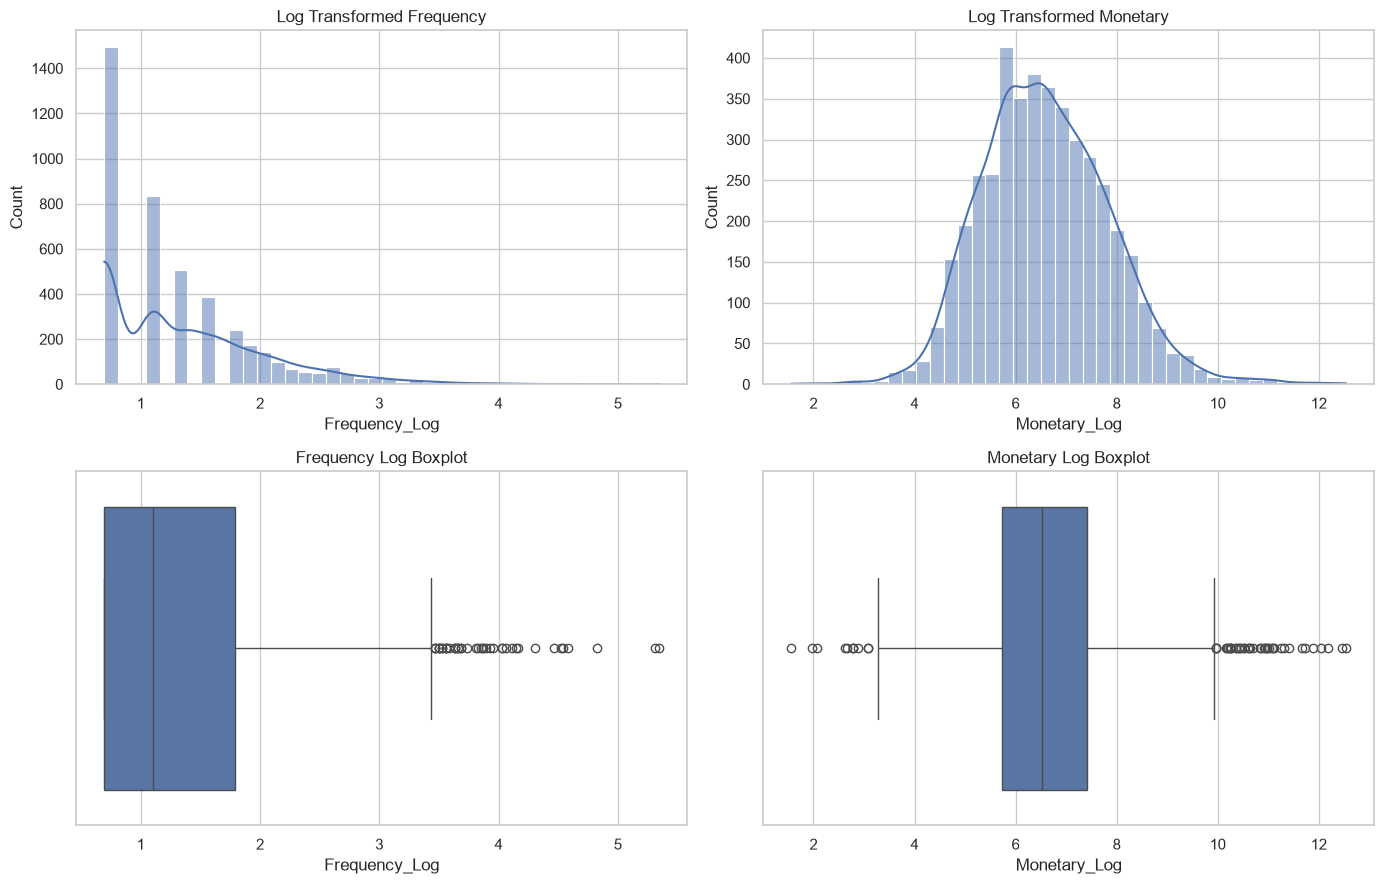

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(
    customer_eda["Frequency_Log"],
    bins=40,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Log Transformed Frequency")

sns.histplot(
    customer_eda["Monetary_Log"],
    bins=40,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Log Transformed Monetary")

sns.boxplot(
    x=customer_eda["Frequency_Log"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Frequency Log Boxplot")

sns.boxplot(
    x=customer_eda["Monetary_Log"],
    ax=axes[1, 1]
)
axes[1, 1].set_title("Monetary Log Boxplot")

plt.tight_layout()
plt.show()

In [24]:
day_2_summary = pd.DataFrame({
    "Metric": ["Frequency", "Monetary"],
    "Skewness_Before": [
        customer_eda["Frequency"].skew(),
        customer_eda["Monetary"].skew()
    ],
    "Skewness_After_Log": [
        customer_eda["Frequency_Log"].skew(),
        customer_eda["Monetary_Log"].skew()
    ]
})

display(day_2_summary)

,Metric,Skewness_Before,Skewness_After_Log
0,Frequency,12.067031,1.208652
1,Monetary,19.324953,0.393553


In [25]:
# =====================================
# DAY 3 - STEP 1: DATA CLEANING
# =====================================

# Keep original dataset unchanged
df_clean = df.copy()

# Count exact duplicate rows
duplicates_count = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("Original Rows:", len(df))
print("Exact Duplicate Rows:", duplicates_count)
print("Rows After Deduplication:", len(df_clean))
print("Removed Percentage:",
      round(duplicates_count / len(df) * 100, 2), "%")

Original Rows: 541909
Exact Duplicate Rows: 5268
Rows After Deduplication: 536641
Removed Percentage: 0.97 %


In [26]:
# =====================================
# STEP 2: VALID PURCHASES
# =====================================

purchase_df = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
    & (df_clean["CustomerID"].notna())
].copy()

# Calculate line revenue
purchase_df["LineRevenue"] = (
    purchase_df["Quantity"] * purchase_df["UnitPrice"]
)

print("Valid Purchase Rows:", len(purchase_df))
print("Unique Customers:",
      purchase_df["CustomerID"].nunique())
print("Unique Invoices:",
      purchase_df["InvoiceNo"].nunique())

print("Total Valid Revenue:",
      round(purchase_df["LineRevenue"].sum(), 2),
      "GBP")

Valid Purchase Rows: 392692
Unique Customers: 4338
Unique Invoices: 18532
Total Valid Revenue: 8887208.89 GBP


In [27]:
# =====================================
# STEP 3: RFM AGGREGATION
# =====================================

snapshot_date = pd.Timestamp("2011-12-10")

rfm_features = (
    purchase_df.groupby("CustomerID")
    .agg(
        LastPurchaseDate=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("LineRevenue", "sum")
    )
    .reset_index()
)

# Calculate Recency
rfm_features["Recency"] = (
    snapshot_date.normalize()
    - rfm_features["LastPurchaseDate"].dt.normalize()
).dt.days

# Reorder columns
rfm_features = rfm_features[
    [
        "CustomerID",
        "LastPurchaseDate",
        "Recency",
        "Frequency",
        "Monetary"
    ]
]

display(rfm_features.head(10))

,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary
0,12346.0,2011-01-18 10:01:00,326,1,77183.60
1,12347.0,2011-12-07 15:52:00,3,7,4310.00
2,12348.0,2011-09-25 13:13:00,76,4,1797.24
3,12349.0,2011-11-21 09:51:00,19,1,1757.55
4,12350.0,2011-02-02 16:01:00,311,1,334.40
5,12352.0,2011-11-03 14:37:00,37,8,2506.04
6,12353.0,2011-05-19 17:47:00,205,1,89.00
7,12354.0,2011-04-21 13:11:00,233,1,1079.40
8,12355.0,2011-05-09 13:49:00,215,1,459.40
9,12356.0,2011-11-17 08:40:00,23,3,2811.43


In [28]:
# Get all registered CustomerIDs
all_customers = (
    df_clean[["CustomerID"]]
    .dropna()
    .drop_duplicates()
)

# Merge RFM features
rfm_draft = all_customers.merge(
    rfm_features,
    on="CustomerID",
    how="left"
)

# Assign eligibility status
rfm_draft["RFM_Status"] = np.where(
    rfm_draft["Frequency"].notna(),
    "ELIGIBLE",
    "NO_VALID_PURCHASE"
)

# Summary
print(rfm_draft["RFM_Status"].value_counts())

print("\nTotal Customers:", len(rfm_draft))
print("Eligible Customers:",
      (rfm_draft["RFM_Status"] == "ELIGIBLE").sum())
print("No Valid Purchase:",
      (rfm_draft["RFM_Status"] == "NO_VALID_PURCHASE").sum())

RFM_Status
ELIGIBLE             4338
NO_VALID_PURCHASE      34
Name: count, dtype: int64

Total Customers: 4372
Eligible Customers: 4338
No Valid Purchase: 34


In [29]:
print("Negative Recency:",
      (rfm_draft["Recency"] < 0).sum())

print("Negative Frequency:",
      (rfm_draft["Frequency"] < 0).sum())

print("Negative Monetary:",
      (rfm_draft["Monetary"] < 0).sum())

print("Duplicate CustomerID:",
      rfm_draft["CustomerID"].duplicated().sum())

print("Missing CustomerID:",
      rfm_draft["CustomerID"].isna().sum())

Negative Recency: 0
Negative Frequency: 0
Negative Monetary: 0
Duplicate CustomerID: 0
Missing CustomerID: 0


In [30]:
# =========================================
# DUPLICATE IMPACT ANALYSIS
# =========================================

# Identify exact duplicate rows removed
duplicate_rows = df.loc[df.duplicated(keep="first")].copy()

# Calculate line revenue
duplicate_rows["LineRevenue"] = (
    duplicate_rows["Quantity"] * duplicate_rows["UnitPrice"]
)

# Identify valid sales among duplicate rows
duplicate_rows["Is_Valid_Sale"] = (
    ~duplicate_rows["InvoiceNo"].astype(str).str.startswith("C")
    & (duplicate_rows["Quantity"] > 0)
    & (duplicate_rows["UnitPrice"] > 0)
)

valid_duplicate_rows = duplicate_rows[
    duplicate_rows["Is_Valid_Sale"]
].copy()

print("Exact Duplicate Rows:", len(duplicate_rows))

print(
    "Valid Duplicate Sales Rows:",
    len(valid_duplicate_rows)
)

print(
    "Revenue of Valid Duplicate Rows:",
    round(valid_duplicate_rows["LineRevenue"].sum(), 2),
    "GBP"
)

print(
    "Duplicate Sales With CustomerID:",
    valid_duplicate_rows["CustomerID"].notna().sum()
)

print(
    "Duplicate Sales Without CustomerID:",
    valid_duplicate_rows["CustomerID"].isna().sum()
)

print(
    "Revenue From Duplicate Sales With CustomerID:",
    round(
        valid_duplicate_rows.loc[
            valid_duplicate_rows["CustomerID"].notna(),
            "LineRevenue"
        ].sum(),
        2
    )
)

print(
    "Revenue From Duplicate Sales Without CustomerID:",
    round(
        valid_duplicate_rows.loc[
            valid_duplicate_rows["CustomerID"].isna(),
            "LineRevenue"
        ].sum(),
        2
    )
)

Exact Duplicate Rows: 5268
Valid Duplicate Sales Rows: 5226
Revenue of Valid Duplicate Rows: 24573.74 GBP
Duplicate Sales With CustomerID: 5192
Duplicate Sales Without CustomerID: 34
Revenue From Duplicate Sales With CustomerID: 24199.01
Revenue From Duplicate Sales Without CustomerID: 374.73


In [31]:
# All valid sales, including missing CustomerID
sales_df = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
].copy()

sales_df["LineRevenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Sales with missing CustomerID
unidentified_sales = sales_df[
    sales_df["CustomerID"].isna()
]

print(
    "Total Valid Sales Revenue:",
    round(sales_df["LineRevenue"].sum(), 2),
    "GBP"
)

print(
    "Identified Customers Revenue:",
    round(
        sales_df.loc[
            sales_df["CustomerID"].notna(),
            "LineRevenue"
        ].sum(),
        2
    ),
    "GBP"
)

print(
    "Unidentified Customers Revenue:",
    round(unidentified_sales["LineRevenue"].sum(), 2),
    "GBP"
)

print(
    "Revenue Reconciliation:",
    round(
        sales_df["LineRevenue"].sum()
        - sales_df.loc[
            sales_df["CustomerID"].notna(),
            "LineRevenue"
        ].sum()
        - unidentified_sales["LineRevenue"].sum(),
        2
    )
)

Total Valid Sales Revenue: 10642110.8 GBP
Identified Customers Revenue: 8887208.89 GBP
Unidentified Customers Revenue: 1754901.91 GBP
Revenue Reconciliation: 0.0


In [32]:
# =========================================
# REVENUE RECONCILIATION AFTER DEDUPLICATION
# =========================================

revenue_audit = df_clean.copy()

revenue_audit["LineRevenue"] = (
    revenue_audit["Quantity"] * revenue_audit["UnitPrice"]
)

revenue_audit["Is_Cancelled"] = (
    revenue_audit["InvoiceNo"].astype(str).str.startswith("C")
)

revenue_audit["Is_Valid_Sale"] = (
    ~revenue_audit["Is_Cancelled"]
    & (revenue_audit["Quantity"] > 0)
    & (revenue_audit["UnitPrice"] > 0)
)

revenue_audit["Is_Invalid_Non_Cancelled"] = (
    ~revenue_audit["Is_Cancelled"]
    & ~revenue_audit["Is_Valid_Sale"]
)

# Calculate categories
valid_sales = revenue_audit[
    revenue_audit["Is_Valid_Sale"]
]

cancelled_sales = revenue_audit[
    revenue_audit["Is_Cancelled"]
]

invalid_sales = revenue_audit[
    revenue_audit["Is_Invalid_Non_Cancelled"]
]

gross_revenue = valid_sales["LineRevenue"].sum()
cancellation_value = cancelled_sales["LineRevenue"].sum()
invalid_value = invalid_sales["LineRevenue"].sum()

net_revenue = gross_revenue + cancellation_value

print("Gross Valid Sales:",
      round(gross_revenue, 2), "GBP")

print("Cancellation Value:",
      round(cancellation_value, 2), "GBP")

print("Net Revenue:",
      round(net_revenue, 2), "GBP")

print("Invalid Transactions Value:",
      round(invalid_value, 2), "GBP")

print("\nRow Counts:")
print("Valid Sales:", len(valid_sales))
print("Cancelled:", len(cancelled_sales))
print("Invalid:", len(invalid_sales))

print("\nPartition Check:",
      len(valid_sales) + len(cancelled_sales) + len(invalid_sales)
      == len(revenue_audit))

Gross Valid Sales: 10642110.8 GBP
Cancellation Value: -893979.73 GBP
Net Revenue: 9748131.07 GBP
Invalid Transactions Value: -22124.12 GBP

Row Counts:
Valid Sales: 524878
Cancelled: 9251
Invalid: 2512

Partition Check: True


In [33]:
# =========================================
# DAY 3 - STEP 1: RFM SCORING
# =========================================

eligible_rfm = rfm_draft[
    rfm_draft["RFM_Status"] == "ELIGIBLE"
].copy()

# Function to convert percentile ranks into scores
def quintile_score(series, higher_is_better=True):

    percentile_rank = series.rank(
        pct=True,
        method="average"
    )

    scores = np.ceil(percentile_rank * 5).clip(1, 5)

    if not higher_is_better:
        scores = 6 - scores

    return scores.astype(int)


# Calculate individual scores
eligible_rfm["R_Score"] = quintile_score(
    eligible_rfm["Recency"],
    higher_is_better=False
)

eligible_rfm["F_Score"] = quintile_score(
    eligible_rfm["Frequency"],
    higher_is_better=True
)

eligible_rfm["M_Score"] = quintile_score(
    eligible_rfm["Monetary"],
    higher_is_better=True
)

# Combined RFM score
eligible_rfm["RFM_Total_Score"] = (
    eligible_rfm["R_Score"]
    + eligible_rfm["F_Score"]
    + eligible_rfm["M_Score"]
)

display(
    eligible_rfm[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Total_Score"
        ]
    ].head(15)
)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score
0,17850.0,373.0,34.0,5391.21,1,5,5,11
1,13047.0,32.0,10.0,3237.54,4,5,5,14
2,12583.0,3.0,15.0,7281.38,5,5,5,15
3,13748.0,96.0,5.0,948.25,2,4,4,10
4,15100.0,334.0,3.0,876.00,1,3,3,7
5,15291.0,26.0,15.0,4668.30,4,5,5,14
6,14688.0,8.0,21.0,5579.10,5,5,5,15
7,17809.0,17.0,12.0,5411.91,4,5,5,14
8,15311.0,1.0,91.0,60632.75,5,5,5,15
9,14527.0,3.0,55.0,8507.13,5,5,5,15


In [34]:
# Score distribution
for score_col in ["R_Score", "F_Score", "M_Score"]:

    print(f"\n{score_col} Distribution")

    display(
        eligible_rfm[score_col]
        .value_counts()
        .sort_index()
        .rename("Customers")
    )


R_Score Distribution


R_Score
1    869
2    858
3    863
4    880
5    868
Name: Customers, dtype: int64


F_Score Distribution


F_Score
1    1493
3    1343
4     630
5     872
Name: Customers, dtype: int64


M_Score Distribution


M_Score
1    867
2    868
3    867
4    868
5    868
Name: Customers, dtype: int64

In [35]:
# =========================================
# RFM SCORE BOUNDARIES ANALYSIS
# =========================================

for score in [1, 2, 3, 4, 5]:

    print(f"\nF_Score = {score}")

    subset = eligible_rfm[
        eligible_rfm["F_Score"] == score
    ]["Frequency"]

    if len(subset) > 0:
        print("Customers:", len(subset))
        print("Min Frequency:", subset.min())
        print("Max Frequency:", subset.max())
        print("Median Frequency:", subset.median())
    else:
        print("No customers in this score")


F_Score = 1
Customers: 1493
Min Frequency: 1.0
Max Frequency: 1.0
Median Frequency: 1.0

F_Score = 2
No customers in this score

F_Score = 3
Customers: 1343
Min Frequency: 2.0
Max Frequency: 3.0
Median Frequency: 2.0

F_Score = 4
Customers: 630
Min Frequency: 4.0
Max Frequency: 5.0
Median Frequency: 4.0

F_Score = 5
Customers: 872
Min Frequency: 6.0
Max Frequency: 209.0
Median Frequency: 9.0


In [36]:
# Frequency value distribution
display(
    eligible_rfm["Frequency"]
    .value_counts()
    .sort_index()
    .head(30)
)

Frequency
1.0     1493
2.0      835
3.0      508
4.0      388
5.0      242
6.0      172
7.0      143
8.0       98
9.0       68
10.0      54
11.0      52
12.0      45
13.0      30
14.0      20
15.0      28
16.0      11
17.0      18
18.0      14
19.0      12
20.0      12
21.0      11
22.0       5
23.0       5
24.0       3
25.0       8
26.0       7
27.0       3
28.0       6
29.0       1
30.0       4
Name: count, dtype: int64

In [37]:
# =========================================
# RFM SEGMENTATION - VERSION 1.0
# =========================================

conditions = [
    eligible_rfm["RFM_Total_Score"].between(12, 15),
    eligible_rfm["RFM_Total_Score"].between(9, 11),
    eligible_rfm["RFM_Total_Score"].between(5, 8),
    eligible_rfm["RFM_Total_Score"].between(3, 4)
]

choices = [
    "Champions",
    "Loyal",
    "At Risk",
    "Lost"
]

eligible_rfm["Segment"] = np.select(
    conditions,
    choices,
    default="UNASSIGNED"
)

# Check assignment
print("Unassigned customers:",
      (eligible_rfm["Segment"] == "UNASSIGNED").sum())

display(
    eligible_rfm["Segment"]
    .value_counts()
    .to_frame("Customers")
)

Unassigned customers: 0


,Customers
Segment,
At Risk,1379
Champions,1218
Loyal,1059
Lost,682


In [38]:
# =========================================
# SEGMENT PROFILE
# =========================================

segment_profile = eligible_rfm.groupby("Segment").agg(

    Customers=("CustomerID", "nunique"),

    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),

    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),

    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),

    Total_Monetary=("Monetary", "sum")

)

segment_profile["Customer_Percentage"] = (
    segment_profile["Customers"]
    / len(eligible_rfm) * 100
)

segment_profile["Revenue_Percentage"] = (
    segment_profile["Total_Monetary"]
    / eligible_rfm["Monetary"].sum() * 100
)

display(
    segment_profile.round(2)
)

,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Monetary,Customer_Percentage,Revenue_Percentage
Segment,,,,,,,,,,
At Risk,1379,110.97,78.0,1.57,1.0,530.84,379.35,732022.23,31.79,8.24
Champions,1218,19.49,12.0,10.15,7.0,5556.59,2599.11,6767928.41,28.08,76.15
Lost,682,248.01,254.5,1.00,1.0,205.60,180.51,140216.96,15.72,1.58
Loyal,1059,54.57,39.0,3.14,3.0,1177.56,848.22,1247041.29,24.41,14.03


In [39]:
# =========================================
# SEGMENTATION VALIDATION
# =========================================

print("Total Eligible Customers:", len(eligible_rfm))

print(
    "Segmented Customers:",
    eligible_rfm["Segment"].isin(choices).sum()
)

print(
    "Unique Customer IDs:",
    eligible_rfm["CustomerID"].nunique()
)

print(
    "Duplicate Customer IDs:",
    eligible_rfm["CustomerID"].duplicated().sum()
)

print(
    "Missing Segments:",
    eligible_rfm["Segment"].isna().sum()
)

Total Eligible Customers: 4338
Segmented Customers: 4338
Unique Customer IDs: 4338
Duplicate Customer IDs: 0
Missing Segments: 0


In [40]:
# =========================================
# SEGMENT BEHAVIOR VALIDATION
# =========================================

segment_validation = eligible_rfm.groupby("Segment").agg(

    Min_Recency=("Recency", "min"),
    Q1_Recency=("Recency", lambda x: x.quantile(0.25)),
    Median_Recency=("Recency", "median"),
    Q3_Recency=("Recency", lambda x: x.quantile(0.75)),
    Max_Recency=("Recency", "max"),

    Min_Frequency=("Frequency", "min"),
    Max_Frequency=("Frequency", "max"),

    Avg_R_Score=("R_Score", "mean"),
    Avg_F_Score=("F_Score", "mean"),
    Avg_M_Score=("M_Score", "mean")

)

display(segment_validation.round(2))

,Min_Recency,Q1_Recency,Median_Recency,Q3_Recency,Max_Recency,Min_Frequency,Max_Frequency,Avg_R_Score,Avg_F_Score,Avg_M_Score
Segment,,,,,,,,,,
At Risk,2.0,45.0,78.0,166.0,374.0,1.0,6.0,2.45,1.87,2.17
Champions,1.0,5.0,12.0,26.0,173.0,2.0,209.0,4.36,4.62,4.59
Lost,73.0,190.0,254.5,312.0,374.0,1.0,1.0,1.21,1.00,1.30
Loyal,1.0,20.0,39.0,72.5,373.0,1.0,34.0,3.32,3.31,3.36


In [41]:
# =========================================
# RFM SCORE COMBINATIONS BY SEGMENT
# =========================================

score_combinations = (
    eligible_rfm
    .groupby(
        ["Segment", "R_Score", "F_Score", "M_Score"]
    )
    .size()
    .reset_index(name="Customers")
    .sort_values(
        ["Segment", "Customers"],
        ascending=[True, False]
    )
)

display(score_combinations)

,Segment,R_Score,F_Score,M_Score,Customers
16,At Risk,2,3,3,133
20,At Risk,3,1,1,130
10,At Risk,2,1,2,107
21,At Risk,3,1,2,104
27,At Risk,4,1,1,89
...,...,...,...,...,...
83,Loyal,4,5,2,1
85,Loyal,5,1,4,1
86,Loyal,5,1,5,1
90,Loyal,5,4,1,1


In [42]:
# =========================================
# SEGMENT ANOMALY INVESTIGATION
# =========================================

checks = {
    "Champions with R_Score <= 2":
        (eligible_rfm["Segment"] == "Champions") &
        (eligible_rfm["R_Score"] <= 2),

    "Loyal with R_Score <= 2":
        (eligible_rfm["Segment"] == "Loyal") &
        (eligible_rfm["R_Score"] <= 2),

    "At Risk with Recency <= 30":
        (eligible_rfm["Segment"] == "At Risk") &
        (eligible_rfm["Recency"] <= 30),

    "Lost with Recency <= 90":
        (eligible_rfm["Segment"] == "Lost") &
        (eligible_rfm["Recency"] <= 90)
}

for label, condition in checks.items():

    subset = eligible_rfm[condition]

    print(f"\n{label}")
    print("Customers:", len(subset))
    print("Revenue:", round(subset["Monetary"].sum(), 2))

    display(
        subset[
            [
                "CustomerID",
                "Recency",
                "Frequency",
                "Monetary",
                "R_Score",
                "F_Score",
                "M_Score",
                "RFM_Total_Score",
                "Segment"
            ]
        ].head(10)
    )


Champions with R_Score <= 2
Customers: 29
Revenue: 119660.1


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
29,14307.0,89.0,6.0,2995.72,2,5,5,12,Champions
78,16928.0,81.0,17.0,2814.70,2,5,5,12,Champions
364,16919.0,157.0,11.0,2592.25,2,5,5,12,Champions
445,17591.0,74.0,7.0,2203.67,2,5,5,12,Champions
499,16553.0,164.0,12.0,5719.82,2,5,5,12,Champions
514,15581.0,121.0,13.0,3675.77,2,5,5,12,Champions
833,12980.0,158.0,9.0,7374.90,2,5,5,12,Champions
841,15379.0,170.0,7.0,3703.29,2,5,5,12,Champions
870,18260.0,173.0,6.0,2628.35,2,5,5,12,Champions
915,13027.0,114.0,6.0,6912.00,2,5,5,12,Champions



Loyal with R_Score <= 2
Customers: 265
Revenue: 543691.12


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
0,17850.0,373.0,34.0,5391.21,1,5,5,11,Loyal
3,13748.0,96.0,5.0,948.25,2,4,4,10,Loyal
10,16098.0,88.0,7.0,2005.63,2,5,4,11,Loyal
28,14045.0,110.0,4.0,1659.75,2,4,4,10,Loyal
50,12868.0,186.0,6.0,1607.06,1,5,4,10,Loyal
52,14078.0,102.0,6.0,1049.37,2,5,4,11,Loyal
68,16456.0,100.0,5.0,2158.18,2,4,5,11,Loyal
73,17873.0,81.0,5.0,1848.96,2,4,4,10,Loyal
74,13093.0,276.0,8.0,7832.47,1,5,5,11,Loyal
87,12947.0,144.0,6.0,1603.99,2,5,4,11,Loyal



At Risk with Recency <= 30
Customers: 212
Revenue: 53570.35


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
299,16411.0,20.0,2.0,211.70,4,3,1,8,At Risk
326,12586.0,18.0,1.0,196.94,4,1,1,6,At Risk
582,16519.0,26.0,2.0,215.08,4,3,1,8,At Risk
1037,13565.0,20.0,2.0,240.22,4,3,1,8,At Risk
1526,18084.0,17.0,1.0,90.48,4,1,1,6,At Risk
1806,15393.0,17.0,2.0,231.86,4,3,1,8,At Risk
1820,16414.0,22.0,2.0,126.25,4,3,1,8,At Risk
2283,13962.0,22.0,2.0,169.55,4,3,1,8,At Risk
2682,14551.0,19.0,2.0,186.23,4,3,1,8,At Risk
2759,15863.0,26.0,2.0,68.84,4,3,1,8,At Risk



Lost with Recency <= 90
Customers: 32
Revenue: 4389.39


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
3418,18255.0,90.0,1.0,103.30,2,1,1,4,Lost
3441,15216.0,88.0,1.0,96.60,2,1,1,4,Lost
3447,16959.0,88.0,1.0,117.35,2,1,1,4,Lost
3453,12756.0,87.0,1.0,112.08,2,1,1,4,Lost
3458,17347.0,87.0,1.0,228.96,2,1,1,4,Lost
3464,13877.0,87.0,1.0,117.24,2,1,1,4,Lost
3480,12995.0,86.0,1.0,211.32,2,1,1,4,Lost
3490,16878.0,85.0,1.0,13.30,2,1,1,4,Lost
3497,13067.0,83.0,1.0,115.46,2,1,1,4,Lost
3504,15504.0,82.0,1.0,52.83,2,1,1,4,Lost


In [43]:
# =========================================
# SEGMENT ANOMALY INVESTIGATION
# =========================================

checks = {
    "Champions with R_Score <= 2":
        (eligible_rfm["Segment"] == "Champions") &
        (eligible_rfm["R_Score"] <= 2),

    "Loyal with R_Score <= 2":
        (eligible_rfm["Segment"] == "Loyal") &
        (eligible_rfm["R_Score"] <= 2),

    "At Risk with Recency <= 30":
        (eligible_rfm["Segment"] == "At Risk") &
        (eligible_rfm["Recency"] <= 30),

    "Lost with Recency <= 90":
        (eligible_rfm["Segment"] == "Lost") &
        (eligible_rfm["Recency"] <= 90)
}

for label, condition in checks.items():

    subset = eligible_rfm[condition]

    print(f"\n{label}")
    print("Customers:", len(subset))
    print("Revenue:", round(subset["Monetary"].sum(), 2))

    display(
        subset[
            [
                "CustomerID",
                "Recency",
                "Frequency",
                "Monetary",
                "R_Score",
                "F_Score",
                "M_Score",
                "RFM_Total_Score",
                "Segment"
            ]
        ].head(10)
    )


Champions with R_Score <= 2
Customers: 29
Revenue: 119660.1


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
29,14307.0,89.0,6.0,2995.72,2,5,5,12,Champions
78,16928.0,81.0,17.0,2814.70,2,5,5,12,Champions
364,16919.0,157.0,11.0,2592.25,2,5,5,12,Champions
445,17591.0,74.0,7.0,2203.67,2,5,5,12,Champions
499,16553.0,164.0,12.0,5719.82,2,5,5,12,Champions
514,15581.0,121.0,13.0,3675.77,2,5,5,12,Champions
833,12980.0,158.0,9.0,7374.90,2,5,5,12,Champions
841,15379.0,170.0,7.0,3703.29,2,5,5,12,Champions
870,18260.0,173.0,6.0,2628.35,2,5,5,12,Champions
915,13027.0,114.0,6.0,6912.00,2,5,5,12,Champions



Loyal with R_Score <= 2
Customers: 265
Revenue: 543691.12


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
0,17850.0,373.0,34.0,5391.21,1,5,5,11,Loyal
3,13748.0,96.0,5.0,948.25,2,4,4,10,Loyal
10,16098.0,88.0,7.0,2005.63,2,5,4,11,Loyal
28,14045.0,110.0,4.0,1659.75,2,4,4,10,Loyal
50,12868.0,186.0,6.0,1607.06,1,5,4,10,Loyal
52,14078.0,102.0,6.0,1049.37,2,5,4,11,Loyal
68,16456.0,100.0,5.0,2158.18,2,4,5,11,Loyal
73,17873.0,81.0,5.0,1848.96,2,4,4,10,Loyal
74,13093.0,276.0,8.0,7832.47,1,5,5,11,Loyal
87,12947.0,144.0,6.0,1603.99,2,5,4,11,Loyal



At Risk with Recency <= 30
Customers: 212
Revenue: 53570.35


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
299,16411.0,20.0,2.0,211.70,4,3,1,8,At Risk
326,12586.0,18.0,1.0,196.94,4,1,1,6,At Risk
582,16519.0,26.0,2.0,215.08,4,3,1,8,At Risk
1037,13565.0,20.0,2.0,240.22,4,3,1,8,At Risk
1526,18084.0,17.0,1.0,90.48,4,1,1,6,At Risk
1806,15393.0,17.0,2.0,231.86,4,3,1,8,At Risk
1820,16414.0,22.0,2.0,126.25,4,3,1,8,At Risk
2283,13962.0,22.0,2.0,169.55,4,3,1,8,At Risk
2682,14551.0,19.0,2.0,186.23,4,3,1,8,At Risk
2759,15863.0,26.0,2.0,68.84,4,3,1,8,At Risk



Lost with Recency <= 90
Customers: 32
Revenue: 4389.39


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total_Score,Segment
3418,18255.0,90.0,1.0,103.30,2,1,1,4,Lost
3441,15216.0,88.0,1.0,96.60,2,1,1,4,Lost
3447,16959.0,88.0,1.0,117.35,2,1,1,4,Lost
3453,12756.0,87.0,1.0,112.08,2,1,1,4,Lost
3458,17347.0,87.0,1.0,228.96,2,1,1,4,Lost
3464,13877.0,87.0,1.0,117.24,2,1,1,4,Lost
3480,12995.0,86.0,1.0,211.32,2,1,1,4,Lost
3490,16878.0,85.0,1.0,13.30,2,1,1,4,Lost
3497,13067.0,83.0,1.0,115.46,2,1,1,4,Lost
3504,15504.0,82.0,1.0,52.83,2,1,1,4,Lost


In [44]:
# =========================================
# RFM SEGMENTATION - VERSION 2.0
# Rule-based classification
# =========================================

conditions_v2 = [

    # Champions
    (
        (eligible_rfm["R_Score"] >= 4) &
        (eligible_rfm["F_Score"] >= 4) &
        (eligible_rfm["M_Score"] >= 4)
    ),

    # Lost
    (
        (eligible_rfm["R_Score"] <= 2) &
        (eligible_rfm["F_Score"] <= 2) &
        (eligible_rfm["M_Score"] <= 2)
    ),

    # At Risk
    (
        (eligible_rfm["R_Score"] <= 2)
    )
]

choices_v2 = [
    "Champions",
    "Lost",
    "At Risk"
]

eligible_rfm["Segment_V2"] = np.select(
    conditions_v2,
    choices_v2,
    default="Loyal"
)

# Compare old and new segments
comparison = pd.crosstab(
    eligible_rfm["Segment"],
    eligible_rfm["Segment_V2"],
    margins=True
)

display(comparison)

Segment_V2,At Risk,Champions,Lost,Loyal,All
Segment,,,,,
At Risk,644,0,107,628,1379
Champions,29,911,0,278,1218
Lost,0,0,682,0,682
Loyal,265,0,0,794,1059
All,938,911,789,1700,4338


In [45]:
# New segment distribution

display(
    eligible_rfm["Segment_V2"]
    .value_counts()
    .to_frame("Customers")
)

,Customers
Segment_V2,
Loyal,1700
At Risk,938
Champions,911
Lost,789


In [46]:
# New segment profile

segment_profile_v2 = eligible_rfm.groupby(
    "Segment_V2"
).agg(

    Customers=("CustomerID", "nunique"),

    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),

    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),

    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),

    Total_Monetary=("Monetary", "sum")

)

segment_profile_v2["Customer_Percentage"] = (
    segment_profile_v2["Customers"]
    / len(eligible_rfm) * 100
)

segment_profile_v2["Revenue_Percentage"] = (
    segment_profile_v2["Total_Monetary"]
    / eligible_rfm["Monetary"].sum() * 100
)

display(segment_profile_v2.round(2))

,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Monetary,Customer_Percentage,Revenue_Percentage
Segment_V2,,,,,,,,,,
At Risk,938,161.11,142.5,2.80,2.0,1238.63,710.00,1161835.10,21.62,13.07
Champions,911,12.85,10.0,11.50,8.0,6230.67,2711.68,5676143.38,21.00,63.87
Lost,789,230.05,240.0,1.00,1.0,224.56,205.86,177177.63,18.19,1.99
Loyal,1700,34.92,34.0,2.73,2.0,1101.21,599.16,1872052.78,39.19,21.06


In [47]:
# =========================================
# VERSION 2.1 - LOYAL ELIGIBILITY TEST
# =========================================

conditions_v21 = [

    # Champions
    (
        (eligible_rfm["R_Score"] >= 4) &
        (eligible_rfm["F_Score"] >= 4) &
        (eligible_rfm["M_Score"] >= 4)
    ),

    # Lost
    (
        (eligible_rfm["R_Score"] <= 2) &
        (eligible_rfm["F_Score"] <= 2) &
        (eligible_rfm["M_Score"] <= 2)
    ),

    # At Risk
    (
        eligible_rfm["R_Score"] <= 2
    ),

    # Loyal
    (
        eligible_rfm["F_Score"] >= 3
    )
]

choices_v21 = [
    "Champions",
    "Lost",
    "At Risk",
    "Loyal"
]

eligible_rfm["Segment_V21_Test"] = np.select(
    conditions_v21,
    choices_v21,
    default="Other_New"
)

display(
    eligible_rfm["Segment_V21_Test"]
    .value_counts()
    .to_frame("Customers")
)

,Customers
Segment_V21_Test,
Loyal,1169
At Risk,938
Champions,911
Lost,789
Other_New,531


In [48]:
other_new_profile = eligible_rfm[
    eligible_rfm["Segment_V21_Test"] == "Other_New"
].agg({

    "Recency": ["min", "median", "max"],
    "Frequency": ["min", "median", "max"],
    "Monetary": ["min", "median", "max"],
    "R_Score": ["min", "median", "max"],
    "F_Score": ["min", "median", "max"],
    "M_Score": ["min", "median", "max"]

})

display(other_new_profile)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
min,1.0,1.0,6.20,3.0,1.0,1.0
median,38.0,1.0,266.76,3.0,1.0,2.0
max,72.0,1.0,6207.67,5.0,1.0,5.0


In [49]:
# =========================================
# FINAL RFM SEGMENTATION - V2.1
# =========================================

conditions = [

    # Champions
    (
        (eligible_rfm["R_Score"] >= 4) &
        (eligible_rfm["F_Score"] >= 4) &
        (eligible_rfm["M_Score"] >= 4)
    ),

    # Lost
    (
        (eligible_rfm["R_Score"] <= 2) &
        (eligible_rfm["F_Score"] <= 2) &
        (eligible_rfm["M_Score"] <= 2)
    ),

    # At Risk
    (
        eligible_rfm["R_Score"] <= 2
    )
]

choices = [
    "Champions",
    "Lost",
    "At Risk"
]

eligible_rfm["Final_Segment"] = np.select(
    conditions,
    choices,
    default="Loyal"
)

# Additional behavioral label
eligible_rfm["Customer_Type"] = np.where(
    eligible_rfm["Frequency"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

# Validation
print("Segment Distribution:")
display(
    eligible_rfm["Final_Segment"]
    .value_counts()
    .to_frame("Customers")
)

print("\nCustomer Type Distribution:")
display(
    eligible_rfm["Customer_Type"]
    .value_counts()
    .to_frame("Customers")
)

print("\nCoverage Check:")
print("Total:", len(eligible_rfm))
print("Unique Customers:", eligible_rfm["CustomerID"].nunique())
print("Missing Segments:", eligible_rfm["Final_Segment"].isna().sum())

Segment Distribution:


,Customers
Final_Segment,
Loyal,1700
At Risk,938
Champions,911
Lost,789



Customer Type Distribution:


,Customers
Customer_Type,
Repeat Customer,2845
One-Time Customer,1493



Coverage Check:
Total: 4338
Unique Customers: 4338
Missing Segments: 0


In [61]:

# =========================================
# RFM SEGMENTATION VALIDATION
# =========================================

print("Champions with R_Score <= 2:")
champions_check = eligible_rfm[
    (eligible_rfm["Final_Segment"] == "Champions") &
    (eligible_rfm["R_Score"] <= 2)
]

display(champions_check)

print("Number of invalid Champions:", len(champions_check))

print("\nSegment distribution:")
display(
    eligible_rfm["Final_Segment"]
    .value_counts()
    .to_frame("Customers")
)

print("\nDuplicate CustomerIDs:")
print(eligible_rfm["CustomerID"].duplicated().sum())

print("\nMissing values:")
display(eligible_rfm.isna().sum())


Champions with R_Score <= 2:


,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary,RFM_Status,R_Score,F_Score,M_Score,RFM_Total_Score,Segment,Segment_V2,Segment_V21_Test,Final_Segment,Customer_Type,KMeans_Cluster


Number of invalid Champions: 0

Segment distribution:


,Customers
Final_Segment,
Loyal,1700
At Risk,938
Champions,911
Lost,789



Duplicate CustomerIDs:
0

Missing values:


CustomerID          0
LastPurchaseDate    0
Recency             0
Frequency           0
Monetary            0
RFM_Status          0
R_Score             0
F_Score             0
M_Score             0
RFM_Total_Score     0
Segment             0
Segment_V2          0
Segment_V21_Test    0
Final_Segment       0
Customer_Type       0
KMeans_Cluster      0
dtype: int64

In [62]:

from pathlib import Path

# Create output folder
output_dir = Path("outputs/customer_view")
output_dir.mkdir(parents=True, exist_ok=True)

# Select columns needed for Customer View
customer_view_df = eligible_rfm[
    [
        "CustomerID",
        "LastPurchaseDate",
        "Recency",
        "Frequency",
        "Monetary",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Total_Score",
        "Final_Segment",
        "Customer_Type"
    ]
].copy()

# Export customer data
customer_view_df.to_csv(
    output_dir / "customer_rfm.csv",
    index=False
)

print("Customer RFM Export Completed")
print("Rows:", len(customer_view_df))
print("Columns:", len(customer_view_df.columns))
print("Saved to:", output_dir / "customer_rfm.csv")


Customer RFM Export Completed
Rows: 4338
Columns: 11
Saved to: outputs\customer_view\customer_rfm.csv


In [50]:
# =========================================
# CUSTOMER TYPE BY SEGMENT
# =========================================

customer_type_analysis = pd.crosstab(
    eligible_rfm["Final_Segment"],
    eligible_rfm["Customer_Type"],
    margins=True
)

display(customer_type_analysis)

Customer_Type,One-Time Customer,Repeat Customer,All
Final_Segment,,,
At Risk,173,765,938
Champions,0,911,911
Lost,789,0,789
Loyal,531,1169,1700
All,1493,2845,4338


In [51]:
# =========================================
# FINAL RFM COVERAGE - ALL CUSTOMERS
# =========================================

final_rfm = rfm_draft.copy()

# Map eligible customer segments
segment_map = eligible_rfm.set_index(
    "CustomerID"
)["Final_Segment"]

customer_type_map = eligible_rfm.set_index(
    "CustomerID"
)["Customer_Type"]

final_rfm["Final_Segment"] = (
    final_rfm["CustomerID"].map(segment_map)
)

final_rfm["Customer_Type"] = (
    final_rfm["CustomerID"].map(customer_type_map)
)

# Assign explicit status for ineligible customers
final_rfm.loc[
    final_rfm["RFM_Status"] == "NO_VALID_PURCHASE",
    "Final_Segment"
] = "NO_VALID_PURCHASE"

final_rfm.loc[
    final_rfm["RFM_Status"] == "NO_VALID_PURCHASE",
    "Customer_Type"
] = "NO_VALID_PURCHASE"

print("Total Customer Records:", len(final_rfm))
print("Unique Customer IDs:", final_rfm["CustomerID"].nunique())

print("\nFinal Status Distribution:")
display(
    final_rfm["Final_Segment"]
    .value_counts(dropna=False)
    .to_frame("Customers")
)

print("\nMissing Segment Values:",
      final_rfm["Final_Segment"].isna().sum())

print("\nDuplicate Customer IDs:",
      final_rfm["CustomerID"].duplicated().sum())

Total Customer Records: 4372
Unique Customer IDs: 4372

Final Status Distribution:


,Customers
Final_Segment,
Loyal,1700
At Risk,938
Champions,911
Lost,789
NO_VALID_PURCHASE,34



Missing Segment Values: 0

Duplicate Customer IDs: 0


In [63]:

# =========================================
# CUSTOMER SEGMENTS SUMMARY EXPORT
# =========================================

segments_summary = (
    eligible_rfm
    .groupby("Final_Segment")
    .agg(
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

segments_summary["Percentage"] = (
    segments_summary["Customers"] /
    segments_summary["Customers"].sum()
) * 100

segments_summary = segments_summary.sort_values(
    by="Customers",
    ascending=False
)

segments_summary.to_csv(
    output_dir / "customer_segments.csv",
    index=False
)

print("Customer Segments Export Completed")
display(segments_summary)

print("\nSaved to:", output_dir / "customer_segments.csv")


Customer Segments Export Completed


,Final_Segment,Customers,Percentage
3,Loyal,1700,39.188566
0,At Risk,938,21.622868
1,Champions,911,21.000461
2,Lost,789,18.188105



Saved to: outputs\customer_view\customer_segments.csv


In [52]:
# =========================================
# K-MEANS - FEATURE PREPARATION
# =========================================

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Select RFM features
rfm_features = eligible_rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Check missing values
print("Missing Values:")
display(rfm_features.isnull().sum())

# Check negative values
print("\nNegative Values:")
display((rfm_features < 0).sum())

# Apply Log Transformation
rfm_log = np.log1p(rfm_features)

# Standardize Features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=eligible_rfm.index
)

print("\nScaled Features Summary:")
display(rfm_scaled_df.describe().round(3))

print("\nShape:", rfm_scaled_df.shape)

Missing Values:


Recency      0
Frequency    0
Monetary     0
dtype: int64


Negative Values:


Recency      0
Frequency    0
Monetary     0
dtype: int64


Scaled Features Summary:


,Recency,Frequency,Monetary
count,4338.000,4338.000,4338.000
mean,0.000,0.000,0.000
std,1.000,1.000,1.000
min,-2.421,-0.955,-3.998
25%,-0.698,-0.955,-0.684
50%,0.072,-0.362,-0.065
75%,0.850,0.653,0.657
max,1.584,5.859,4.732



Shape: (4338, 3)


In [53]:
# =========================================
# K-MEANS - FIND OPTIMAL NUMBER OF CLUSTERS
# =========================================

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_scores = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled_df)

    inertia_scores.append(kmeans.inertia_)

    score = silhouette_score(
        rfm_scaled_df,
        cluster_labels
    )

    silhouette_scores.append(score)

    print(
        f"K={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )

K=2 | Inertia=6476.51 | Silhouette=0.4325
K=3 | Inertia=4858.28 | Silhouette=0.3376
K=4 | Inertia=3925.39 | Silhouette=0.3354
K=5 | Inertia=3269.01 | Silhouette=0.3183
K=6 | Inertia=2840.52 | Silhouette=0.3148
K=7 | Inertia=2532.96 | Silhouette=0.3103
K=8 | Inertia=2325.13 | Silhouette=0.3019


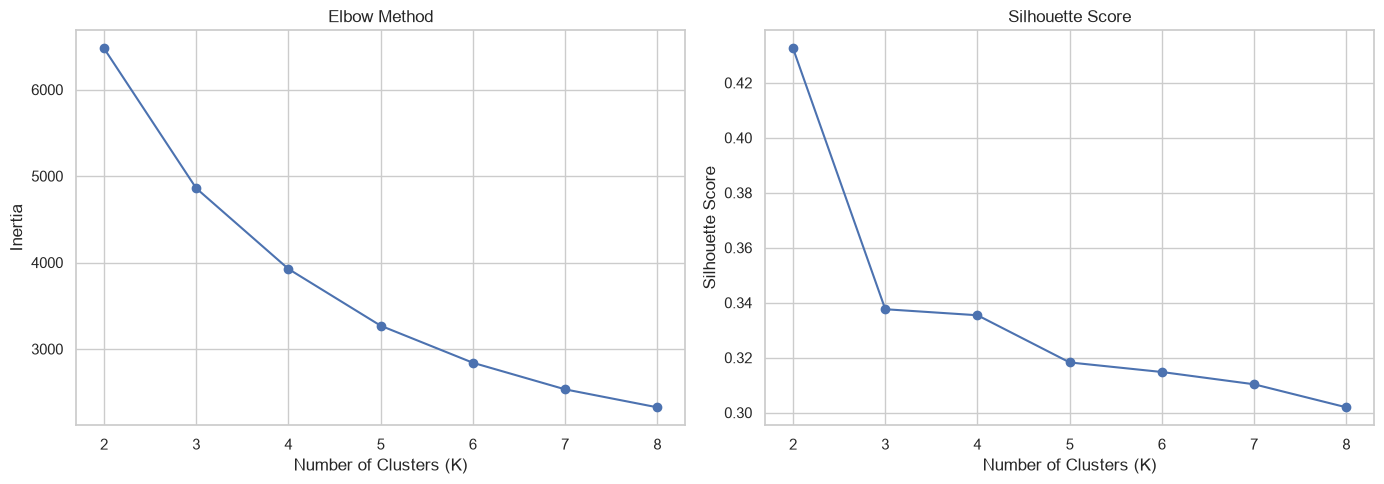

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(
    list(k_values),
    inertia_scores,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)

# Silhouette Score
axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [55]:
# =========================================
# K-MEANS FINAL EXPERIMENT - K=4
# =========================================

from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

# Train model
cluster_labels = kmeans_final.fit_predict(rfm_scaled_df)

# Add cluster labels to eligible customers
eligible_rfm = eligible_rfm.copy()
eligible_rfm["KMeans_Cluster"] = cluster_labels

print("Cluster Distribution:")

display(
    eligible_rfm["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Customers")
)

Cluster Distribution:


,Customers
KMeans_Cluster,
0,1591
1,1161
2,708
3,878


In [56]:
# =========================================
# CLUSTER PROFILING
# =========================================

cluster_profile = eligible_rfm.groupby(
    "KMeans_Cluster"
).agg(
    Customers=("CustomerID", "count"),

    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),

    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),

    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),

    Total_Revenue=("Monetary", "sum")
)

cluster_profile["Revenue_Share_%"] = (
    cluster_profile["Total_Revenue"]
    / eligible_rfm["Monetary"].sum()
) * 100

cluster_profile["Customer_Share_%"] = (
    cluster_profile["Customers"]
    / len(eligible_rfm)
) * 100

display(cluster_profile.round(2))

,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue,Revenue_Share_%,Customer_Share_%
KMeans_Cluster,,,,,,,,,,
0,1591,187.59,183.0,1.34,1.0,355.51,300.95,565610.25,6.36,36.68
1,1161,67.49,53.0,4.17,4.0,1826.62,1360.99,2120700.22,23.86,26.76
2,708,12.39,9.0,13.78,10.0,8112.19,3720.97,5743428.35,64.63,16.32
3,878,20.63,19.0,2.04,2.0,521.04,447.31,457470.07,5.15,20.24


In [57]:
# =========================================
# COMPARE RULE-BASED VS K-MEANS
# =========================================

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Cross-tabulation
comparison = pd.crosstab(
    eligible_rfm["Final_Segment"],
    eligible_rfm["KMeans_Cluster"],
    margins=True
)

print("Rule-Based vs K-Means:")
display(comparison)

# Agreement Metrics
ari = adjusted_rand_score(
    eligible_rfm["Final_Segment"],
    eligible_rfm["KMeans_Cluster"]
)

nmi = normalized_mutual_info_score(
    eligible_rfm["Final_Segment"],
    eligible_rfm["KMeans_Cluster"]
)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

Rule-Based vs K-Means:


KMeans_Cluster,0,1,2,3,All
Final_Segment,,,,,
At Risk,546,387,5,0,938
Champions,0,220,666,25,911
Lost,789,0,0,0,789
Loyal,256,554,37,853,1700
All,1591,1161,708,878,4338


Adjusted Rand Index (ARI): 0.3283
Normalized Mutual Information (NMI): 0.4654


## K-Means Clustering Evaluation

### Model Configuration
- Algorithm: K-Means
- Number of Clusters: 4
- Random State: 42
- Initialization: 20
- Features: Recency, Frequency, Monetary
- Preprocessing: Log1p Transformation + StandardScaler

### Evaluation Results
- Silhouette Score: 0.3354
- Adjusted Rand Index (ARI): 0.3283
- Normalized Mutual Information (NMI): 0.4654

### Key Findings
- Cluster 2 strongly aligns with Champions (94.1%).
- Cluster 3 strongly aligns with Loyal (97.2%).
- At Risk and Lost customers show more distributed patterns.
- K-Means provides complementary behavioral insights.

### Final Decision
Rule-Based RFM remains the primary business
segmentation approach, while K-Means is retained
as an exploratory clustering and validation method.

In [58]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

random_states = [0, 21, 42, 100, 123]

cluster_results = {}

for seed in random_states:

    model = KMeans(
        n_clusters=4,
        random_state=seed,
        n_init=20
    )

    cluster_results[seed] = model.fit_predict(rfm_scaled_df)

stability_results = []

for seed in random_states:
    stability_results.append({
        "Random_State": seed,
        "Inertia": KMeans(
            n_clusters=4,
            random_state=seed,
            n_init=20
        ).fit(rfm_scaled_df).inertia_
    })

stability_df = pd.DataFrame(stability_results)

# Compare every model with the baseline model (seed 42)
stability_df["ARI_vs_Baseline"] = [
    adjusted_rand_score(
        cluster_results[42],
        cluster_results[seed]
    )
    for seed in random_states
]

display(stability_df.round(4))

,Random_State,Inertia,ARI_vs_Baseline
0,0,3925.2642,0.9456
1,21,3925.3607,0.9371
2,42,3925.3942,1.0000
3,100,3925.4143,0.9380
4,123,3925.3942,1.0000


## K-Means Stability Evaluation

### Experimental Setup
Five different random states were tested:
0, 21, 42, 100, 123.

All models used:
- K = 4
- N_Init = 20
- The same preprocessed RFM dataset.

### Results
- Inertia values were highly consistent.
- ARI against baseline ranged from 0.9371 to 1.0000.
- Two runs produced identical cluster assignments to the baseline.

### Conclusion
K-Means demonstrated high sensitivity stability
across the tested initialization seeds.

The model is retained as an exploratory
segmentation approach, while Rule-Based RFM
remains the primary business segmentation model.

In [59]:
import pandas as pd

print("=== CUSTOMER ANALYSIS DATAFRAMES ===")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nVariable: {name}")
        print(f"Shape: {obj.shape}")
        print(f"Columns: {list(obj.columns)}")

=== CUSTOMER ANALYSIS DATAFRAMES ===

Variable: df
Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Variable: missing_analysis
Shape: (8, 2)
Columns: ['Missing_Count', 'Missing_Percentage']

Variable: purchase_df
Shape: (392692, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'LineRevenue']

Variable: df_base
Shape: (536641, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Variable: excluded_customers_df
Shape: (89, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Variable: tmp
Shape: (89, 13)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Is_Cancelled', 'Is_Non_Cancelled', 'Positive_Quantity', 'Positive_Price', 'Valid_Pur

In [60]:
# Check Champions with low Recency Score

champions_check = final_rfm[
    (final_rfm["Final_Segment"] == "Champions") &
    (final_rfm["R_Score"] <= 2)
]

print("Champions with R_Score <= 2:")
print("Customers:", len(champions_check))

print(
    "Revenue:",
    round(champions_check["Monetary"].sum(), 2)
)

display(champions_check.head(30))

KeyError: 'R_Score'